# 09a LightGBM

Now machine learning. LightGBM is a gradient-boosted tree model. We train one model for all 726 products together,
on lagged sales, recent averages, price, the calendar and SNAP days, and use it on exactly the same backtest as the
classical models: same origins, same 28-day forecasts, same scores. We also try the same retraining idea as in 08d
(train only after the latest shift, with a placebo), and then put every forecast so far into one file that the
comparison, uncertainty and stock notebooks read.

## Load

In [1]:
import os, sys, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from config import ROOT, RAW, INTERIM, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS
from break_detection import weekly_ca_prices
from forecasting import is_intermittent, build_lgb_panel, lgb_forecast
from metrics import mase_scale, wrmsse, paired_test, standardized_mean_diff

RERUN = False
written = []
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df = long_df.sort_values(["item_id", "date"]).reset_index(drop=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
item_cat = long_df.groupby("item_id")["category"].first()
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
price_wk = weekly_ca_prices(prices, calendar, long_df["item_id"].unique())
del prices
daily = {item: g[["date", "sales"]].reset_index(drop=True) for item, g in long_df.groupby("item_id")}
windows = pd.read_csv(PROCESSED / "breaks_by_origin.csv",
                      parse_dates=["origin", "first_date", "last_change_week", "last_alarm_week", "adaptive_start", "placebo_start"])
intermittent = {item: is_intermittent(d.loc[d["date"] <= ORIGINS[0], "sales"]) for item, d in daily.items()}
print(f"{len(daily)} products, {len(long_df):,} rows")

726 products, 1,290,010 rows


## Training it

Every sales feature is lagged by at least 28 days (sales 28, 35, 42 and 49 days ago, and 7-, 28- and 56-day averages
and spread of sales from 28 days back), so one model can forecast all 28 days without feeding its own forecasts back
in and without seeing the future. Price, price relative to its yearly average, day of week, month, events, SNAP and
days since the first sale are treated as known in advance, as in the M5 competition. The loss is Tweedie, which
suits counts with zeros; 300 rounds, learning rate 0.05, 63 leaves.

At each origin we train three times: on all history (static), only from each product's latest shift (retrained),
and with the placebo start for products without one. Twenty-one trainings take about eleven minutes, so the results
are saved.

In [2]:
path = PROCESSED / "lightgbm_forecasts.parquet"
if RERUN or not path.exists():
    panel = build_lgb_panel(long_df, calendar, price_wk)
    w_idx = windows.set_index(["origin", "item_id"])
    parts, importances = [], []
    t0 = time.time()
    for origin in ORIGINS:
        w = w_idx.loc[origin]
        variant_starts = {"static": None,
                          "adaptive": w["adaptive_start"].dropna().to_dict(),
                          "placebo": w["placebo_start"].dropna().to_dict()}
        for variant, st in variant_starts.items():
            fc, mdl = lgb_forecast(panel, origin, train_start_by_item=st)
            fc["origin"], fc["model"], fc["variant"] = origin, "lightgbm", variant
            parts.append(fc)
            if variant == "static":
                importances.append(pd.Series(mdl.feature_importance("gain"), index=mdl.feature_name(), name=origin))
        print(f"origin {origin.date()} done ({time.time() - t0:.0f}s)")
    lgb_fc = pd.concat(parts, ignore_index=True)

    # a variant that does not apply (no shift, or no placebo start) is the static model by definition;
    # a global retrain still moves it a little because other products' rows changed, so we put the static forecast back
    lgb_fc = lgb_fc.merge(windows[["item_id", "origin", "has_break", "placebo_start"]], on=["item_id", "origin"])
    static_lgb = lgb_fc[lgb_fc["variant"] == "static"].set_index(["item_id", "origin", "date"])["forecast"]
    use_static = ((lgb_fc["variant"] == "adaptive") & ~lgb_fc["has_break"]) | \
                 ((lgb_fc["variant"] == "placebo") & lgb_fc["placebo_start"].isna())
    lgb_fc.loc[use_static, "forecast"] = static_lgb.reindex(
        pd.MultiIndex.from_frame(lgb_fc.loc[use_static, ["item_id", "origin", "date"]])).to_numpy()
    lgb_fc = lgb_fc.drop(columns=["has_break", "placebo_start"])
    lgb_fc.to_parquet(path, index=False)
    pd.concat(importances, axis=1).to_csv(PROCESSED / "lightgbm_importance.csv")
lgb_fc = pd.read_parquet(path)
imp = pd.read_csv(PROCESSED / "lightgbm_importance.csv", index_col=0).mean(axis=1).sort_values(ascending=False)
written += [path, PROCESSED / "lightgbm_importance.csv"]
print("share of total gain, top 10 features:")
print((imp / imp.sum()).round(3).head(10).to_string())

share of total gain, top 10 features:
rmean_28_l28         0.417
rmean_56_l28         0.314
item_code            0.095
rmean_7_l28          0.077
lag_28               0.027
dow                  0.017
days_since_launch    0.012
price_rel_365        0.010
month                0.006
lag_35               0.006


## Every forecast in one place, and the scores

In [3]:
local_fc = pd.concat([pd.read_parquet(PROCESSED / "local_static_forecasts.parquet"),
                      pd.read_parquet(PROCESSED / "local_variant_forecasts.parquet")], ignore_index=True)
fc = pd.concat([local_fc, lgb_fc], ignore_index=True)
fc = fc.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
fc = fc.merge(windows[["item_id", "origin", "has_break", "placebo_start"]], on=["item_id", "origin"])
fc["category"] = fc["item_id"].map(item_cat)

# per product and origin: MASE scale, RMSSE scale and dollar weight (last 28 days before the origin)
scale_rows = []
for item, d in daily.items():
    p = price_wk[item]
    for origin in ORIGINS:
        hist = d.loc[d["date"] <= origin, "sales"].to_numpy()
        last = d[(d["date"] > origin - pd.Timedelta(days=28)) & (d["date"] <= origin)]
        price = p[p.index <= origin].dropna().iloc[-1]
        scale_rows.append({"item_id": item, "origin": origin, "mase_scale": mase_scale(hist),
                           "rmsse_scale": np.mean(np.diff(hist) ** 2),
                           "dollar_weight": last["sales"].sum() * price})
scales = pd.DataFrame(scale_rows)

err = (fc.assign(abs_err=(fc["actual"] - fc["forecast"]).abs(), sq_err=(fc["actual"] - fc["forecast"]) ** 2)
         .groupby(["item_id", "category", "origin", "model", "variant", "has_break"], as_index=False)
         .agg(mae=("abs_err", "mean"), mse=("sq_err", "mean"), actual_mean=("actual", "mean")))
err = err.merge(scales, on=["item_id", "origin"])
err["mase"] = err["mae"] / err["mase_scale"]
err["rmsse"] = np.sqrt(err["mse"] / err["rmsse_scale"])
err["intermittent"] = err["item_id"].map(intermittent)
err.to_csv(PROCESSED / "backtest_errors.csv", index=False)
written.append(PROCESSED / "backtest_errors.csv")
ev = err[err["origin"].isin(EVAL_ORIGINS)]
print(f"{len(fc):,} forecast rows, {len(err):,} product-origin-model-variant scores")

1,295,952 forecast rows, 46,284 product-origin-model-variant scores


## LightGBM against the classical models on all 726 products

In [4]:
static = ev[ev["variant"] == "static"]
item_mase_all = static.groupby(["item_id", "category", "model", "intermittent"], as_index=False)["mase"].mean()
item_mase = item_mase_all[item_mase_all["model"] != "tsb"]      # TSB only runs on intermittent products
tbl = item_mase.pivot_table(index="category", columns="model", values="mase", aggfunc="median")
tbl.loc["ALL"] = item_mase.groupby("model")["mase"].median()
print("median MASE (static):")
print(tbl.round(3).to_string())

w = static[static["model"] != "tsb"].groupby(["model", "origin"]).apply(lambda g: wrmsse(g["rmsse"], g["dollar_weight"]), include_groups=False)
print("\ndollar-weighted RMSSE (mean over scored origins):")
print(w.groupby("model").mean().round(3).to_string())

inter = item_mase_all[item_mase_all["intermittent"]]
print(f"\nintermittent products only (n={inter['item_id'].nunique()}), median MASE:")
print(inter.groupby("model")["mase"].median().round(3).to_string())

lgb_vs_naive = item_mase.pivot(index="item_id", columns="model", values="mase")
print("\nLightGBM against seasonal naive, paired:", {k: round(v, 4) for k, v in
      paired_test(lgb_vs_naive["lightgbm"] - lgb_vs_naive["seasonal_naive"]).items()})
tbl.round(3).to_csv(TABLES / "model_mase_by_category.csv")
written.append(TABLES / "model_mase_by_category.csv")

median MASE (static):
model        ets  lightgbm  seasonal_naive
category                                  
FOODS      0.771     0.751           0.957
HOBBIES    0.755     0.752           1.004
HOUSEHOLD  0.744     0.730           0.978
ALL        0.755     0.744           0.976

dollar-weighted RMSSE (mean over scored origins):
model
ets               0.828
lightgbm          0.815
seasonal_naive    1.036

intermittent products only (n=26), median MASE:
model
ets               0.962
lightgbm          0.886
seasonal_naive    1.147
tsb               0.986



LightGBM against seasonal naive, paired: {'n': 726, 'n_nonzero': 726, 'median_diff': np.float64(-0.2256), 'mean_diff': np.float64(-0.2158), 'share_improved': np.float64(0.9353), 'p_value': np.float64(0.0), 'rank_biserial': np.float64(-0.9312), 'ci_low': np.float64(-0.2343), 'ci_high': np.float64(-0.2147)}


## Does retraining after a shift help LightGBM?

In [5]:
def variant_diff(df, variant, mask_col):
    sub = df[df["model"] != "seasonal_naive"]                    # seasonal naive only uses the last week anyway
    piv = sub.pivot_table(index=["item_id", "category", "model", "origin", "has_break"],
                          columns="variant", values="mase").reset_index()
    piv = piv[mask_col(piv)]
    piv["diff"] = piv[variant] - piv["static"]
    return piv.groupby(["item_id", "category", "model"], as_index=False)["diff"].mean()

adapt = variant_diff(ev, "adaptive", lambda p: p["has_break"])
# the placebo only where a random cut was possible (otherwise it is the static model)
ev_pl = ev.merge(windows.loc[windows["placebo_start"].notna(), ["item_id", "origin"]], on=["item_id", "origin"])
placebo = variant_diff(ev_pl, "placebo", lambda p: ~p["has_break"])

rows = []
for label, df in [("adaptive (break items)", adapt), ("placebo (no-break items)", placebo)]:
    for model in ["ets", "lightgbm", "tsb"]:
        for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
            d = df[(df["model"] == model) & ((df["category"] == cat) | (cat == "ALL"))]["diff"]
            if len(d) == 0:
                continue
            rows.append({"comparison": label, "model": model, "category": cat, **paired_test(d)})
adapt_tbl = pd.DataFrame(rows)
adapt_tbl.to_csv(TABLES / "adaptive_vs_static_tests.csv", index=False)
written.append(TABLES / "adaptive_vs_static_tests.csv")
cols = ["comparison", "model", "category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "rank_biserial", "p_value"]
print(adapt_tbl[cols].round(4).to_string(index=False))

              comparison    model  category   n  median_diff  ci_low  ci_high  share_improved  rank_biserial  p_value
  adaptive (break items)      ets       ALL 488       0.0024  0.0004   0.0038          0.4447         0.1741   0.0009
  adaptive (break items)      ets     FOODS 234       0.0011 -0.0011   0.0051          0.4744         0.1151   0.1269
  adaptive (break items)      ets   HOBBIES  67       0.0031  0.0018   0.0051          0.3284         0.3810   0.0067
  adaptive (break items)      ets HOUSEHOLD 187       0.0021 -0.0007   0.0042          0.4492         0.1952   0.0206
  adaptive (break items) lightgbm       ALL 488       0.0033  0.0015   0.0053          0.4324         0.2340   0.0000
  adaptive (break items) lightgbm     FOODS 234       0.0054  0.0017   0.0087          0.4060         0.2893   0.0001
  adaptive (break items) lightgbm   HOBBIES  67       0.0036  0.0008   0.0082          0.3731         0.3872   0.0059
  adaptive (break items) lightgbm HOUSEHOLD 187       0.

ets: median retrained change +0.0024 vs placebo +0.0004, Mann-Whitney p = 0.0486
lightgbm: median retrained change +0.0033 vs placebo +0.0009, Mann-Whitney p = 0.0366


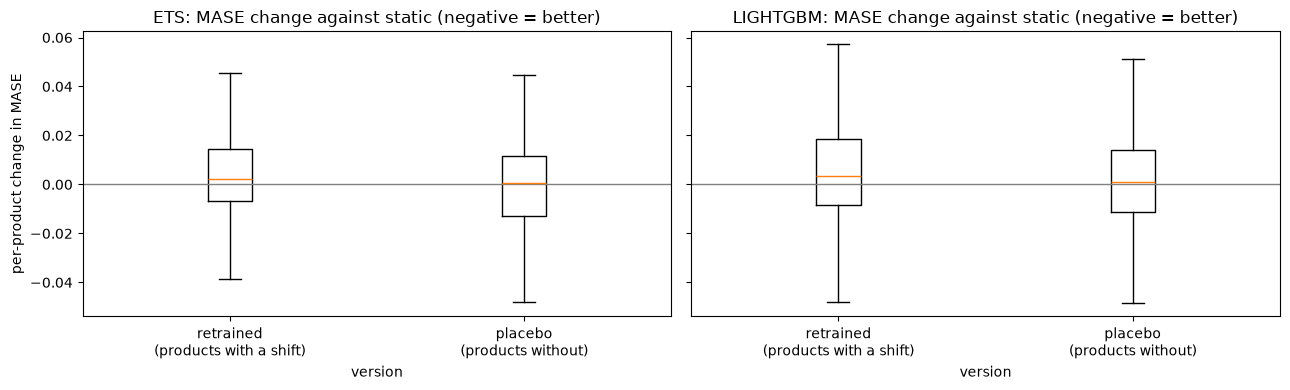

In [6]:
# is the retrained change bigger than the placebo change? (different products, so an unpaired test)
for model in ["ets", "lightgbm"]:
    a = adapt.loc[adapt["model"] == model, "diff"]
    p = placebo.loc[placebo["model"] == model, "diff"]
    u = stats.mannwhitneyu(a, p)
    print(f"{model}: median retrained change {a.median():+.4f} vs placebo {p.median():+.4f}, Mann-Whitney p = {u.pvalue:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, model in zip(axes, ["ets", "lightgbm"]):
    data = [adapt.loc[adapt["model"] == model, "diff"], placebo.loc[placebo["model"] == model, "diff"]]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ["retrained\n(products with a shift)", "placebo\n(products without)"])
    ax.axhline(0, color="grey", lw=1)
    ax.set_title(f"{model.upper()}: MASE change against static (negative = better)")
    ax.set_xlabel("version")
axes[0].set_ylabel("per-product change in MASE")
plt.tight_layout()
plt.savefig(FIGS / "adaptive_vs_placebo.png", dpi=120)
written.append(FIGS / "adaptive_vs_placebo.png")
plt.show()

## Are products with a shift simply harder to forecast?

If they were, a raw comparison of their errors would be unfair. We first compare the two groups, then regress the
log of static MASE on the shift flag with volume, variability, zero share, history length and category as controls.

In [7]:
pre = long_df[long_df["date"] <= ORIGINS[0]]
cov = pre.groupby("item_id")["sales"].agg(mean_sales="mean", std_sales="std", zero_share=lambda s: (s == 0).mean(),
                                         n_days="size").reset_index()
cov["cv"] = cov["std_sales"] / cov["mean_sales"]
cov["category"] = cov["item_id"].map(item_cat)
broke = windows[windows["origin"].isin(EVAL_ORIGINS)].groupby("item_id")["has_break"].any()
cov["break_item"] = cov["item_id"].map(broke)

bal = pd.DataFrame({c: {"break_items_mean": cov.loc[cov["break_item"], c].mean(),
                        "no_break_mean": cov.loc[~cov["break_item"], c].mean(),
                        "SMD": standardized_mean_diff(cov.loc[cov["break_item"], c], cov.loc[~cov["break_item"], c])}
                    for c in ["mean_sales", "cv", "zero_share", "n_days"]}).T
print(f"products with a shift: {cov['break_item'].sum()}, without: {(~cov['break_item']).sum()}")
print(bal.round(3).to_string())

reg = item_mase.merge(cov, on=["item_id", "category"])
for model in ["ets", "lightgbm"]:
    d = reg[reg["model"] == model].assign(log_mase=lambda x: np.log(x["mase"]), log_mean=lambda x: np.log(x["mean_sales"]),
                                          break_item=lambda x: x["break_item"].astype(int))
    raw = smf.ols("log_mase ~ break_item", d).fit()
    adj = smf.ols("log_mase ~ break_item + log_mean + cv + zero_share + n_days + C(category)", d).fit()
    for name, m in [("raw", raw), ("adjusted", adj)]:
        lo, hi = m.conf_int().loc["break_item"]
        print(f"{model} {name:8s}: products with a shift have {100*(np.exp(m.params['break_item'])-1):+.1f}% MASE "
              f"(95% CI {100*(np.exp(lo)-1):+.1f}% to {100*(np.exp(hi)-1):+.1f}%), p = {m.pvalues['break_item']:.4f}")

products with a shift: 488, without: 238
            break_items_mean  no_break_mean    SMD
mean_sales            14.605         16.795 -0.115
cv                     0.669          0.663  0.043
zero_share             0.084          0.077  0.096
n_days              1627.074       1486.143  0.448
ets raw     : products with a shift have +0.4% MASE (95% CI -3.6% to +4.6%), p = 0.8472
ets adjusted: products with a shift have +1.6% MASE (95% CI -2.3% to +5.7%), p = 0.4227


lightgbm raw     : products with a shift have +2.0% MASE (95% CI -2.2% to +6.4%), p = 0.3620
lightgbm adjusted: products with a shift have +2.8% MASE (95% CI -1.3% to +7.2%), p = 0.1823


## A first uncertainty band

For each product, model and version we add the 5th and 95th percentile of its own past errors (only origins before
this one) to the forecast. That gives a simple 90% band. 11a checks how honest it is and builds a better one.

In [8]:
fc = fc.sort_values(["item_id", "model", "variant", "origin", "date"]).reset_index(drop=True)
fc["error"] = fc["actual"] - fc["forecast"]
band_rows = []
for (item, model, variant), g in fc.groupby(["item_id", "model", "variant"], sort=False):
    for i, origin in enumerate(ORIGINS[1:], start=1):
        past = g.loc[g["origin"] < origin, "error"]
        band_rows.append((item, model, variant, origin, past.quantile(0.05), past.quantile(0.95), past.std()))
bands = pd.DataFrame(band_rows, columns=["item_id", "model", "variant", "origin", "err_q05", "err_q95", "err_sd"])
fc = fc.merge(bands, on=["item_id", "model", "variant", "origin"], how="left")
fc["lo_90"] = np.maximum(fc["forecast"] + fc["err_q05"], 0)
fc["hi_90"] = fc["forecast"] + fc["err_q95"]
fc.to_parquet(PROCESSED / "backtest_forecasts.parquet", index=False)
written.append(PROCESSED / "backtest_forecasts.parquet")

cov_ok = fc[fc["origin"].isin(EVAL_ORIGINS)].assign(inside=lambda x: (x["actual"] >= x["lo_90"]) & (x["actual"] <= x["hi_90"]))
print("share of days inside the 90% band (scored origins):")
print(cov_ok.groupby(["model", "variant"])["inside"].mean().round(3).unstack().to_string())

share of days inside the 90% band (scored origins):


variant         adaptive  placebo  static
model                                    
ets                0.838    0.840   0.839
lightgbm           0.842    0.844   0.845
seasonal_naive     0.857    0.857   0.857
tsb                0.819    0.816   0.818


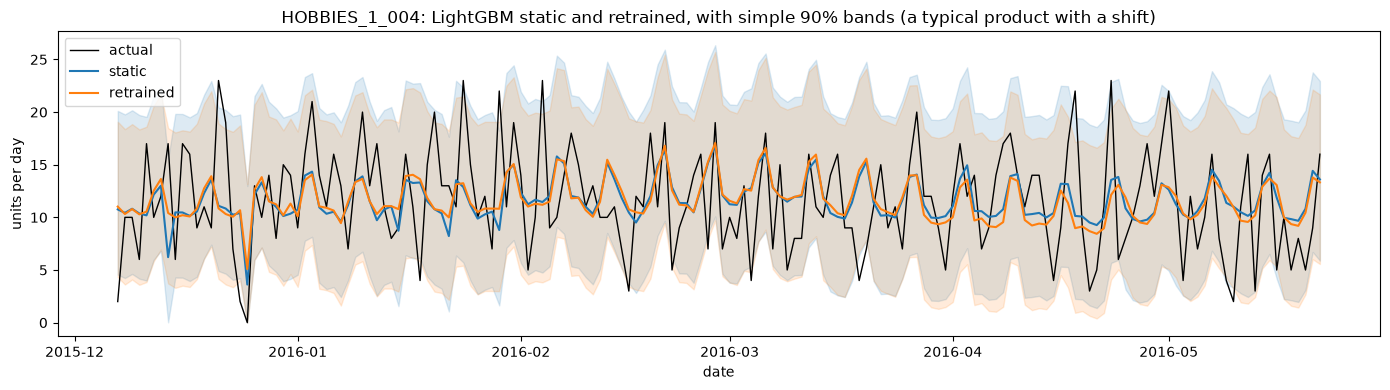

In [9]:
# one product with a shift, chosen as the median effect of retraining
ex_item = adapt[adapt["model"] == "lightgbm"].sort_values("diff")["item_id"].iloc[len(adapt[adapt["model"] == "lightgbm"]) // 2]
ex = fc[(fc["item_id"] == ex_item) & (fc["model"] == "lightgbm") & fc["origin"].isin(EVAL_ORIGINS)]
fig, ax = plt.subplots(figsize=(14, 4))
act = ex[ex["variant"] == "static"]
ax.plot(act["date"], act["actual"], color="black", lw=1, label="actual")
for variant, color in [("static", "tab:blue"), ("adaptive", "tab:orange")]:
    e = ex[ex["variant"] == variant]
    ax.plot(e["date"], e["forecast"], color=color, label="retrained" if variant == "adaptive" else variant)
    ax.fill_between(e["date"], e["lo_90"], e["hi_90"], color=color, alpha=0.15)
ax.set_title(f"{ex_item}: LightGBM static and retrained, with simple 90% bands (a typical product with a shift)")
ax.set_xlabel("date")
ax.set_ylabel("units per day")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "forecast_example_item.png", dpi=120)
written.append(FIGS / "forecast_example_item.png")
plt.show()

## What we found

LightGBM is the best model so far, but not by much. On all 726 products its median MASE is 0.744, against 0.755 for
ETS and 0.976 for seasonal naive, and it beats seasonal naive for 93.5% of products. Weighted by dollar sales it is
ahead too (0.815 against 0.828 for ETS). On the 26 intermittent products it is clearly better than TSB (0.886 against
0.986). It leans almost entirely on recent levels: the 28- and 56-day averages carry about 73% of the gain, and the
product itself another 10%.

Retraining LightGBM after a shift did not help either. On the 488 products with a shift, MASE changed by +0.0033
(95% CI +0.0015 to +0.0053), better for only 43% of them. The placebo changed it by +0.0009, so the retrained model
is in fact slightly worse than a random short window (Mann-Whitney p = 0.037). And products with a shift are not just
harder ones: after controls their static error is 2.8% higher, with a confidence interval from -1.3% to +7.2%, so no
detectable difference.

The simple 90% band is too narrow. For LightGBM it holds the actual sales on 84.5% of days instead of 90%. We come
back to that in 11a.

## What comes next

`09b_lightgbm_after_breaks` tries three gentler ways of reacting to a shift, and `10_model_comparison` puts every model in one table.

In [10]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\lightgbm_forecasts.parquet 3,393 KB
data\processed\lightgbm_importance.csv 2 KB
data\processed\backtest_errors.csv 9,169 KB
outputs\tables\model_mase_by_category.csv 0 KB
outputs\tables\adaptive_vs_static_tests.csv 4 KB
outputs\figures\adaptive_vs_placebo.png 41 KB
data\processed\backtest_forecasts.parquet 21,007 KB
outputs\figures\forecast_example_item.png 258 KB
